In [15]:
import pandas as pd
from pathlib import Path

RAW = Path.cwd().parent / "data" / "raw"
OUT = Path.cwd().parent / "data" / "processed"

COLUNAS = {
    "DATA INICIAL": "data_inicial",
    "DATA FINAL": "data_final",
    "ESTADO": "estado",
    "MUNICÍPIO": "municipio",
    "PRODUTO": "produto",
    "NÚMERO DE POSTOS PESQUISADOS": "n_postos",
    "UNIDADE DE MEDIDA": "unidade",
    "PREÇO MÉDIO REVENDA": "preco_medio",
    "DESVIO PADRÃO REVENDA": "desvio_padrao",
    "PREÇO MÍNIMO REVENDA": "preco_min",
    "PREÇO MÁXIMO REVENDA": "preco_max",
    "COEF DE VARIAÇÃO REVENDA": "coef_variacao",
}

def ler_arquivo(caminho: Path) -> pd.DataFrame:
    df = pd.read_excel(caminho, header=9).rename(columns=COLUNAS)
    df["arquivo"] = caminho.name
    return df

df = pd.concat(
    [ler_arquivo(f) for f in sorted(RAW.glob("*.xlsx"))],
    ignore_index=True,
)

df["data_inicial"] = pd.to_datetime(df["data_inicial"], errors="coerce")
df["data_final"] = pd.to_datetime(df["data_final"], errors="coerce")
df = df.dropna(subset=["data_inicial"])

for col in ["preco_medio", "preco_min", "preco_max", "desvio_padrao", "coef_variacao", "n_postos"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["estado", "municipio", "produto"]:
    df[col] = df[col].str.strip()

df = df.drop_duplicates(subset=["data_inicial", "municipio", "produto"])

OUT.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT / "precos_capitais.csv", index=False)

print(df.shape)
print(df.groupby("data_inicial").size().to_string())

(1160, 13)
data_inicial
2026-09-20    162
2026-09-27    168
2026-10-04    165
2026-10-11    169
2026-10-18    162
2026-10-25    169
2026-11-01    165


In [16]:
p = df[df["produto"].isin(["ETANOL HIDRATADO", "GASOLINA COMUM"])].pivot_table(
    index=["data_inicial", "estado", "municipio"],
    columns="produto",
    values="preco_medio",
).reset_index()

p = p.dropna(subset=["ETANOL HIDRATADO", "GASOLINA COMUM"])
p["razao"] = p["ETANOL HIDRATADO"] / p["GASOLINA COMUM"]
p["etanol_compensa"] = p["razao"] < 0.70

ult = p[p["data_inicial"] == p["data_inicial"].max()]
print(ult.sort_values("razao")[["municipio", "estado", "razao", "etanol_compensa"]].to_string(index=False))

     municipio              estado    razao  etanol_compensa
        CUIABA         MATO GROSSO 0.593343             True
       GOIANIA               GOIAS 0.595122             True
     SAO PAULO           SAO PAULO 0.631496             True
  CAMPO GRANDE  MATO GROSSO DO SUL 0.634185             True
    RIO BRANCO                ACRE 0.667125             True
   PORTO VELHO            RONDONIA 0.673768             True
         BELEM                PARA 0.675079             True
      CURITIBA              PARANA 0.686391             True
      BRASILIA    DISTRITO FEDERAL 0.686454             True
BELO HORIZONTE        MINAS GERAIS 0.688272             True
      SALVADOR               BAHIA 0.690513             True
        RECIFE          PERNAMBUCO 0.703650            False
   JOAO PESSOA             PARAIBA 0.705314            False
     FORTALEZA               CEARA 0.706304            False
      TERESINA               PIAUI 0.710682            False
     BOA VISTA          

In [17]:
p.groupby("data_inicial")["etanol_compensa"].agg(compensa="sum", total="count")

,compensa,total
data_inicial,,
2026-09-20,12,26
2026-09-27,11,27
2026-10-04,11,26
2026-10-11,11,27
2026-10-18,11,25
2026-10-25,12,27
2026-11-01,11,26


In [18]:
g = df[df["produto"] == "GASOLINA COMUM"].copy()
g["preco_x_postos"] = g["preco_medio"] * g["n_postos"]
agrupado = g.groupby("data_inicial")[["preco_x_postos", "n_postos"]].sum()
nacional = agrupado["preco_x_postos"] / agrupado["n_postos"]
nacional

data_inicial
2026-09-20    6.615148
2026-09-27    6.621133
2026-10-04    6.628893
2026-10-11    6.607849
2026-10-18    6.570189
2026-10-25    6.547245
2026-11-01    6.532835
dtype: float64

In [19]:
g = df[df["produto"] == "GASOLINA COMUM"]
n_semanas = g["data_inicial"].nunique()
presentes = g.groupby("municipio")["data_inicial"].nunique()
completas = presentes[presentes == n_semanas].index

gb = g[g["municipio"].isin(completas)].copy()
gb["preco_x_postos"] = gb["preco_medio"] * gb["n_postos"]
agr = gb.groupby("data_inicial")[["preco_x_postos", "n_postos"]].sum()
nacional_balanceado = agr["preco_x_postos"] / agr["n_postos"]
print(len(completas), "capitais em todas as semanas")
nacional_balanceado

24 capitais em todas as semanas


data_inicial
2026-09-20    6.618248
2026-09-27    6.615524
2026-10-04    6.621580
2026-10-11    6.602330
2026-10-18    6.568662
2026-10-25    6.545961
2026-11-01    6.531194
dtype: float64

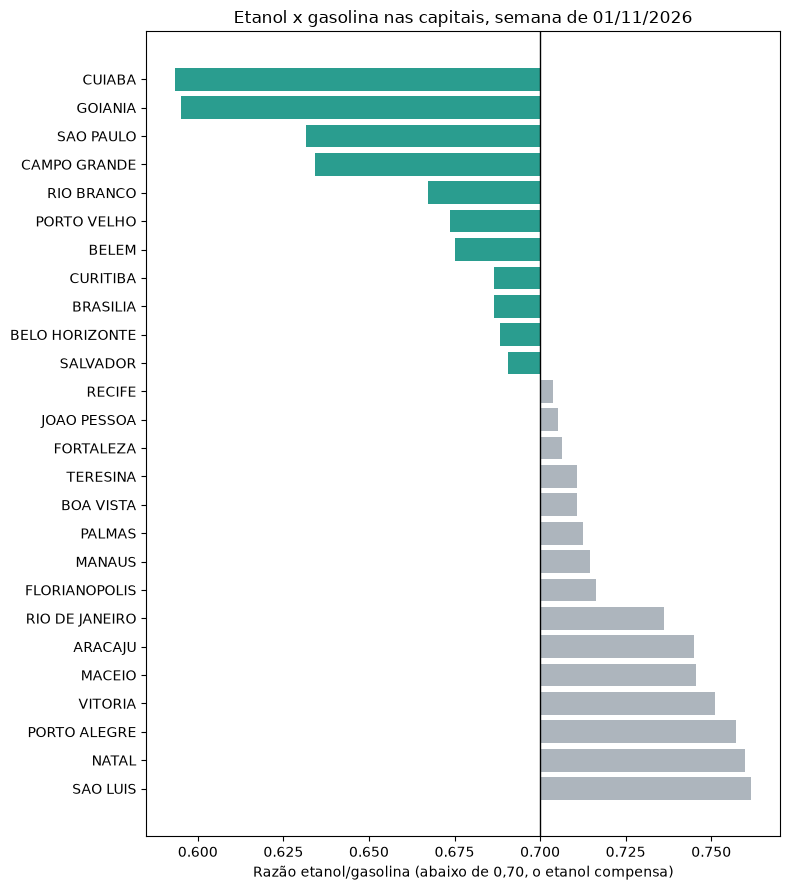

In [20]:
import matplotlib.pyplot as plt

d = ult.sort_values("razao", ascending=False)
cores = ["#2a9d8f" if c else "#adb5bd" for c in d["etanol_compensa"]]

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(d["municipio"], d["razao"] - 0.70, left=0.70, color=cores)
ax.axvline(0.70, color="black", linewidth=1)
ax.set_xlabel("Razão etanol/gasolina (abaixo de 0,70, o etanol compensa)")
ax.set_title("Etanol x gasolina nas capitais, semana de 01/11/2026")
plt.tight_layout()
plt.show()

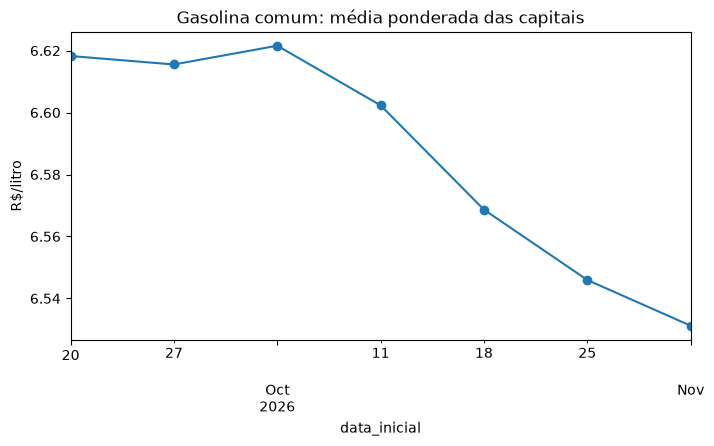

In [21]:
ax = nacional_balanceado.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("R$/litro")
ax.set_title("Gasolina comum: média ponderada das capitais")
plt.show()